## 0. 준비

모델에 데이터를 넣기 전에 아래 순서로 준비합니다. 코드는 위에서부터 차례로 실행하고, 각 단계에서 무엇을 하는지는 설명으로 확인합니다.

| 단계 | 하는 일 |
|---|---|
| 0-1 | 도구 불러오기 |
| 0-2 | 데이터 읽기 |
| 0-3 | 데이터 살펴보기 |
| 0-4 | 입력과 정답 나누기 |
| 0-5 | 훈련용과 평가용 나누기 |
| 0-6 | 빈 값 확인 |
| 0-7 | 빈 값 채우기 |

### 0-1. 도구 불러오기

필요한 도구를 불러옵니다.

- `pandas`: 표 형태의 데이터를 다루는 도구
- `matplotlib`: 그래프를 그리는 도구
- `scikit-learn`: 모델 학습, 데이터 분리, 오차 계산을 하는 도구

그래프에 한글이 깨지지 않도록 글꼴도 함께 설정합니다.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

fonts = {f.name for f in fm.fontManager.ttflist}
plt.rcParams["font.family"] = next((n for n in ["Malgun Gothic", "AppleGothic", "NanumGothic"] if n in fonts), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False

### 0-2. 데이터 읽기

`data/AmesHousing.txt` 파일을 읽어 `df`라는 표에 저장합니다. 이 표는 원본 그대로이며, 뒤에서 필요한 정보를 꺼내 쓸 때 다시 사용합니다.

표의 행은 주택 한 건, 열은 그 집의 정보 하나입니다.

In [2]:
path = Path("data/AmesHousing.txt")
if not path.exists():
    path = Path("2. 회귀/data/AmesHousing.txt")
df = pd.read_csv(path, sep="\t")

print(f"행 {df.shape[0]:,}개 / 열 {df.shape[1]}개")
df.head()

행 2,930개 / 열 82개


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


### 0-3. 데이터 살펴보기

**데이터 출처와 의미**

- 미국 아이오와주 Ames시에서 2006~2010년에 거래된 주택 기록입니다. (Dean De Cock, 2011)
- 한 행은 주택 한 건의 거래이며 2,930건입니다. 열은 82개로, 면적·품질·건축 연도·동네·시설 등이 담겨 있습니다.
- 맞히려는 값은 **거래 가격(`SalePrice`)** 입니다. 당시 거래된 가격이며 오늘날의 매매 가격을 예측하는 자료는 아닙니다.
- 82개 중 **12개 정보**와 가격만 사용합니다. 나머지 열은 뒤의 실험에서 필요할 때 추가합니다.

**이번에 사용하는 12개 정보**

| 항목 | 의미 | 단위·범위 |
|---|---|---|
| Gr Liv Area | 지상 주거 면적 | ft² |
| Lot Area | 대지 면적 | ft² |
| Overall Qual | 자재·마감 품질 등급 | 1~10, 높을수록 좋음 |
| Overall Cond | 주택 전체 상태 등급 | 1~10, 높을수록 좋음 |
| Year Built | 건축 연도 | 연도 |
| Year Remod/Add | 리모델링·증축 연도 | 변경이 없으면 건축 연도와 같음 |
| Total Bsmt SF | 지하실 면적 | ft² |
| Garage Area | 차고 면적 | ft² |
| Garage Cars | 차고에 주차할 수 있는 차량 수 | 대 |
| TotRms AbvGrd | 지상층 방 수 (욕실 제외) | 개 |
| Full Bath | 지상층 욕실 수 | 개 |
| Yr Sold | 거래 연도 | 연도 |
| **SalePrice** | **거래 가격 (맞히려는 값)** | **달러** |

1ft²는 약 0.093m²입니다. `Overall Qual`은 자재·마감의 품질이고 `Overall Cond`는 집의 전반적인 상태이므로 서로 다른 항목입니다.

In [3]:
features = ["Gr Liv Area", "Lot Area", "Overall Qual", "Overall Cond",
            "Year Built", "Year Remod/Add", "Total Bsmt SF", "Garage Area",
            "Garage Cars", "TotRms AbvGrd", "Full Bath", "Yr Sold"]

overview = df[features + ["SalePrice"]].describe().T[["min", "50%", "max"]]
overview.columns = ["최솟값", "중앙값", "최댓값"]
overview.round(0)

,최솟값,중앙값,최댓값
Gr Liv Area,334.0,1442.0,5642.0
Lot Area,1300.0,9436.0,215245.0
Overall Qual,1.0,6.0,10.0
Overall Cond,1.0,5.0,9.0
Year Built,1872.0,1973.0,2010.0
Year Remod/Add,1950.0,1993.0,2010.0
Total Bsmt SF,0.0,990.0,6110.0
Garage Area,0.0,480.0,1488.0
Garage Cars,0.0,2.0,5.0
TotRms AbvGrd,2.0,6.0,15.0


항목마다 값의 범위가 다릅니다. 가격은 약 12,800달러부터 755,000달러까지이고 중앙값은 160,000달러입니다. 거래 가격의 분포는 아래 그래프로 확인합니다.

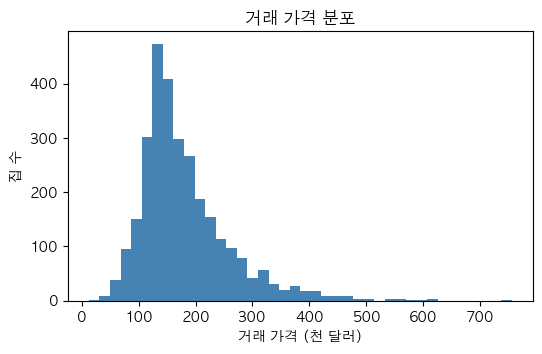

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(df["SalePrice"] / 1000, bins=40, color="steelblue")
ax.set_xlabel("거래 가격 (천 달러)"); ax.set_ylabel("집 수"); ax.set_title("거래 가격 분포")
plt.show()

가격이 낮은 쪽에 대부분의 집이 몰려 있고, 비싼 집은 수가 적습니다.

### 0-4. 입력과 정답 나누기

모델은 **정보(입력)와 가격(정답)의 관계**를 배워서, 정답을 모르는 집의 가격을 예측합니다.

- **입력 `X`:** 가격을 맞히는 데 쓰는 12개 정보
- **정답 `y`:** 거래 가격 (`SalePrice`)

입력에 가격 자체를 넣으면 정답을 보고 정답을 맞히는 셈이 되므로 입력에는 넣지 않습니다.

In [5]:
X = df[features]
y = df["SalePrice"]

print("입력 X:", X.shape, "/ 정답 y:", y.shape)

입력 X: (2930, 12) / 정답 y: (2930,)


### 0-5. 훈련용과 평가용 나누기

전체 2,930건을 **훈련용 80%** 와 **평가용 20%** 로 나눕니다.

| 구분 | 건수 | 용도 |
|---|---|---|
| 훈련용 (`X_train`, `y_train`) | 2,344건 | 모델이 정보와 가격의 관계를 배우는 데 사용 |
| 평가용 (`X_test`, `y_test`) | 586건 | 학습이 끝난 뒤 예측이 맞는지 확인하는 데 사용 |

**나누는 이유**

- 모델이 학습에 사용한 집으로 점수를 매기면 모델의 예측 실력이 아니라 학습한 내용을 기억하는 정도를 확인하게 됩니다. 시험 문제를 미리 보고 공부한 뒤 같은 문제로 시험을 보는 것과 같습니다.
- 실제로 필요한 것은 처음 보는 집의 가격을 맞히는 능력입니다. 그래서 일부를 학습에서 빼 두었다가, 학습 후 이 집들의 가격을 예측해 실제와 비교합니다.
- 이후의 모든 비교(처음 예측, 정보를 추가한 예측)는 **같은 평가용 집**으로 합니다. 같은 집으로 비교해야 결과가 달라진 이유를 정보 추가로 볼 수 있습니다.

**나누는 방식**

- 집을 무작위로 섞어서 나눕니다. 건축 연도나 가격 순서대로 나누면 한쪽에 비슷한 집이 몰립니다.
- `random_state=42`는 섞는 방식을 고정하는 번호입니다. 모두 같은 집이 평가용으로 뽑혀서 같은 결과가 나옵니다.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"훈련용 {len(X_train):,}건 / 평가용 {len(X_test):,}건")

훈련용 2,344건 / 평가용 586건


### 0-6. 빈 값 확인

모델은 값이 비어 있는 정보를 받으면 학습하거나 예측할 수 없습니다. 먼저 어떤 정보에 빈 값이 몇 건 있는지 확인합니다.

In [7]:
missing = X_train.isna().sum()
display(missing[missing > 0].rename("빈 값 수"))

X_train[X_train.isna().any(axis=1)][["Total Bsmt SF", "Garage Area", "Garage Cars"]]

Total Bsmt SF    1
Garage Area      1
Garage Cars      1
Name: 빈 값 수, dtype: int64

,Total Bsmt SF,Garage Area,Garage Cars
1341,NaN,280.0,1.0
2236,859.0,NaN,NaN


훈련용에 빈 값이 있는 집은 2건입니다. 한 건은 지하실 면적이, 다른 한 건은 차고 면적과 차고 대수가 비어 있습니다. 평가용에는 빈 값이 없습니다.

차고 면적이 `0`인 집은 차고가 없다는 뜻이며 정보가 비어 있는 것과 다릅니다.

### 0-7. 빈 값 채우기

빈 값이 있는 집을 처리하는 방법은 두 가지입니다.

| 방법 | 특징 |
|---|---|
| 그 집을 삭제 | 다른 정보는 정상인데 그 집의 정보까지 함께 사라짐 |
| 빈 값을 채움 | 집을 유지할 수 있으나 채운 값은 실제 값이 아님 |

이번에는 **빈 값을 중앙값으로 채웁니다.**

- **중앙값:** 값을 크기 순으로 세웠을 때 가운데에 있는 값입니다. 면적이 아주 큰 집처럼 극단적인 값의 영향을 평균보다 덜 받습니다.
- 중앙값은 **훈련용 집에서만** 계산합니다. 평가용은 모델이 처음 보는 집이어야 하므로, 평가용 정보를 준비 과정에 사용하지 않습니다.
- 계산한 중앙값으로 훈련용과 평가용의 빈 값을 같은 방식으로 채웁니다.
- 채운 값은 실제 값을 복원한 것이 아니라 이번 비교를 위한 간단한 처리입니다.

In [8]:
fill = X_train.median()          # 훈련용에서 구한 항목별 중앙값
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

display(fill[["Total Bsmt SF", "Garage Area", "Garage Cars"]].rename("채운 값(중앙값)"))
print("남은 빈 값:", X_train.isna().sum().sum() + X_test.isna().sum().sum(), "건")

Total Bsmt SF    988.0
Garage Area      476.0
Garage Cars        2.0
Name: 채운 값(중앙값), dtype: float64

남은 빈 값: 0 건


빈 값이 모두 채워졌습니다. 아래 셀은 이후 그래프에 사용하는 함수입니다. 실행만 하면 됩니다.

In [9]:
def plot_actual_pred(ax, pred, title):
    ax.scatter(y_test / 1000, pred / 1000, s=12, alpha=0.5)
    top = max(y_test.max(), pred.max()) / 1000
    ax.plot([0, top], [0, top], color="crimson")
    ax.set_xlabel("실제 가격 (천 달러)"); ax.set_ylabel("예측 가격 (천 달러)"); ax.set_title(title)


print("준비 완료:", len(X_train), "건으로 학습,", len(X_test), "건으로 확인")

준비 완료: 2344 건으로 학습, 586 건으로 확인


## 1. 첫 예측

12개 정보로 가격을 예측합니다. **MAE**는 예측이 평균 몇 달러 틀렸는지를 나타내며 작을수록 좋습니다.

그래프의 점 하나는 집 한 채입니다. 빨간 선에 가까울수록 잘 맞았고, 선 위쪽은 실제보다 높게, 아래쪽은 낮게 예측한 집입니다.

첫 예측 MAE: 24,095 달러


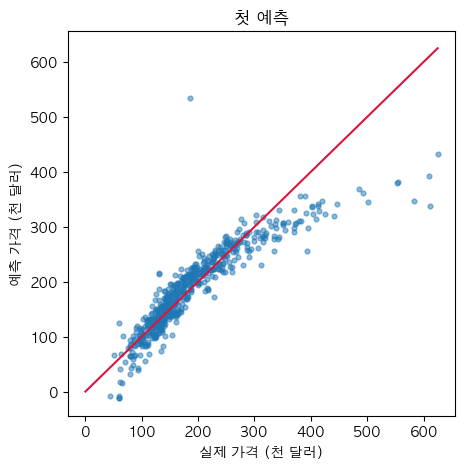

In [10]:
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
mae_before = mean_absolute_error(y_test, pred)
print(f"첫 예측 MAE: {mae_before:,.0f} 달러")

fig, ax = plt.subplots(figsize=(5, 5))
plot_actual_pred(ax, pred, "첫 예측")
plt.show()

예측 결과를 표로 모읍니다. **오차 = 예측 − 실제**이며, 음수는 실제보다 낮게 예측했다는 뜻입니다.

In [11]:
result = X_test.copy()
result["실제 가격"] = y_test
result["첫 예측"] = pred.round(0)
result["오차"] = result["첫 예측"] - result["실제 가격"]

---
# 함께 1회

## ① 많이 틀린 집 보기

그래프에서 빨간 선 아래쪽으로 멀리 떨어진 집, 즉 **실제보다 많이 낮게 예측해서 크게 틀린 집** 10건을 봅니다. 오차가 음수이고 그 크기가 큰 집입니다.

OpenCode 요청 예시

> result 표에서 실제보다 가장 많이 낮게 예측한 10건을 보여줘. (오차가 음수이고 그 크기가 큰 집) 실제 가격, 첫 예측, 오차, Overall Qual, Gr Liv Area와 함께 원본 df의 Neighborhood(동네)도 같이 보고 싶어.

In [12]:
result["동네"] = df.loc[result.index, "Neighborhood"]

cols = ["실제 가격", "첫 예측", "오차", "동네", "Overall Qual", "Gr Liv Area"]
worst10 = result.sort_values("오차").head(10)   # 오차가 가장 큰 음수(많이 낮게 예측) 10건
worst10[cols]

,실제 가격,첫 예측,오차,동네,Overall Qual,Gr Liv Area
44,611657,338579.0,-273078.0,NridgHt,9,2364
433,582933,347377.0,-235556.0,NridgHt,9,2822
432,610000,391518.0,-218482.0,NridgHt,10,2674
2445,625000,432536.0,-192464.0,NoRidge,10,3627
423,555000,381605.0,-173395.0,NridgHt,10,2402
456,552000,380346.0,-171654.0,NridgHt,10,2492
366,501837,344786.0,-157051.0,StoneBr,9,2234
1559,392500,256701.0,-135799.0,Crawfor,8,1652
1691,492000,361440.0,-130560.0,NridgHt,9,2656
1641,441929,318729.0,-123200.0,StoneBr,8,2234


10건이 **몇몇 동네에 몰려 있습니다.** 다른 집에서도 그런지 동네별 평균 오차로 확인합니다. 평균 오차가 음수일수록 그 동네 집이 낮게 예측되었다는 뜻입니다.

OpenCode 요청 예시

> result 표를 동네별로 묶어서 건수와 평균 오차를 보여주고, 실제보다 가장 많이 낮게 예측된 6개 동네를 보여줘. (평균 오차가 음수이고 그 크기가 큰 동네)

In [13]:
by_nbhd = result.groupby("동네").agg(건수=("오차", "size"), 평균_오차=("오차", "mean")).round(0)
by_nbhd.sort_values("평균_오차").head(6)   # 평균 오차가 가장 큰 음수(많이 낮게 예측) 6개 동네

,건수,평균_오차
동네,,
NridgHt,45,-50464.0
StoneBr,15,-39014.0
Crawfor,14,-38272.0
NoRidge,14,-34535.0
Timber,13,-22707.0
SWISU,11,-7715.0


## ② 이유 추측하기

> **눈에 띈 점:** 많이 낮게 예측한 집은 NridgHt, StoneBr, NoRidge 같은 몇몇 동네에 몰려 있고, 이 동네들의 평균 오차도 음수이다.
>
> **가설:** 가격이 높은 동네의 집이 비싸게 거래되는데, 지금 모델은 동네 정보를 받지 못해서 반영하지 못한다.
>
> **해볼 것:** 원본 데이터에 있는 동네(Neighborhood) 정보를 입력에 추가한다.

## ③ 정보 하나 추가하기

원본 `df`에는 있지만 처음 12개 입력에 넣지 않은 정보가 많습니다. 동네 정보를 추가해 다시 예측합니다.

OpenCode 요청 예시

> 원본 df의 Neighborhood(동네)를 입력에 추가해서 같은 선형회귀로 다시 학습하고 예측값을 pred_a에 저장해줘. X_train과 X_test는 그대로 두고 복사본을 사용해줘.

In [14]:
nbhd = pd.get_dummies(df["Neighborhood"], prefix="동네").astype(int)   # 동네 이름을 모델이 읽을 수 있는 형태로 변환
X_train_a = X_train.join(nbhd)
X_test_a = X_test.join(nbhd)

pred_a = LinearRegression().fit(X_train_a, y_train).predict(X_test_a)

## ④ 결과 확인하기

세 가지를 확인합니다.

1. MAE가 줄었는지
2. 그래프에서 점이 빨간 선에 가까워졌는지
3. 처음 본 10건의 오차가 줄었는지

MAE  변경 전: 24,095 달러  →  변경 후: 20,587 달러


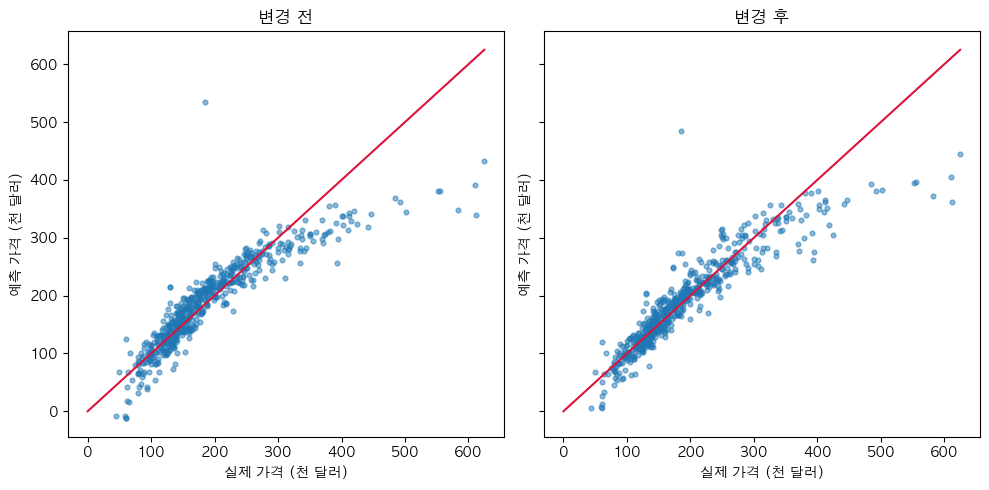

In [15]:
mae_a = mean_absolute_error(y_test, pred_a)
print(f"MAE  변경 전: {mae_before:,.0f} 달러  →  변경 후: {mae_a:,.0f} 달러")

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
plot_actual_pred(axes[0], pred, "변경 전")
plot_actual_pred(axes[1], pred_a, "변경 후")
plt.tight_layout()
plt.show()

In [16]:
result["변경 후 오차"] = pred_a.round(0) - result["실제 가격"]
result.loc[worst10.index, ["동네", "실제 가격", "오차", "변경 후 오차"]]

,동네,실제 가격,오차,변경 후 오차
44,NridgHt,611657,-273078.0,-249303.0
433,NridgHt,582933,-235556.0,-209992.0
432,NridgHt,610000,-218482.0,-204632.0
2445,NoRidge,625000,-192464.0,-180026.0
423,NridgHt,555000,-173395.0,-158378.0
456,NridgHt,552000,-171654.0,-157229.0
366,StoneBr,501837,-157051.0,-119625.0
1559,Crawfor,392500,-135799.0,-130768.0
1691,NridgHt,492000,-130560.0,-110647.0
1641,StoneBr,441929,-123200.0,-82841.0


MAE는 줄었지만 10건이 모두 좋아지지는 않았을 수 있습니다. 전체 평균이 좋아져도 모든 집이 좋아지는 것은 아닙니다.

---
# 직접 1회

위의 **첫 예측(`pred`, `result`, `mae_before`)에서 다시 출발**합니다. 함께 1회에서는 '동네' 정보를 추가했고, 이번에는 원본 데이터의 **다른 정보**를 골라 추가합니다.

## ① 많이 틀린 집 보기

실제보다 **높게 예측한 집**과 **낮게 예측한 집** 중 하나를 골라 10건을 봅니다. 아래 정보를 함께 붙여 보면 눈에 띄는 점을 찾기 쉽습니다.

| 원본 df의 정보 | 의미 | 값 |
|---|---|---|
| Kitchen Qual | 주방 품질 | Ex 최상 · Gd 좋음 · TA 보통 · Fa 낮음 · Po 불량 |
| Exter Qual | 외관 품질 | 위와 같음 |
| Bsmt Qual | 지하실 품질 | 위와 같음, 빈 값은 지하실 없음 |
| Bldg Type | 건물 종류 | 단독주택, 연립주택 등 |

OpenCode 요청 예시

> result 표에서 실제보다 가장 많이 높게 예측한 10건을 보여줘. (오차가 양수이고 그 크기가 큰 집) 원본 df의 Kitchen Qual, Exter Qual, Bsmt Qual, Bldg Type도 같이 붙여서 보고 싶어.

## ② 이유 추측하기

표를 보고 한 가지를 골라 아래 문장을 완성합니다.

> 선택한 집들은 ______ 가 비슷한 것 같다. 이 정보를 추가하면 가격을 더 잘 맞출 것 같다.

예시

- 낮게 예측한 집은 주방 품질이 Ex 또는 Gd인 집이 대부분이다. 주방 품질이 좋은 집이 더 비싸게 거래될 수 있는데 모델이 이 정보를 모르고 있다.
- 높게 예측한 집 중에는 연립주택·복층 같은 건물 종류가 많다. 건물 종류에 따라 가격이 다를 수 있는데 모델이 이 정보를 모르고 있다.

## ③ 정보 하나 추가하기

고른 정보 **하나만** 추가합니다. 새 예측은 `pred_b`에 저장합니다.

OpenCode 요청 예시 (고른 정보에 맞게 바꿔 요청합니다)

> 원본 df의 Kitchen Qual(주방 품질)을 입력에 추가해서 같은 선형회귀로 다시 학습하고 예측값을 pred_b에 저장해줘. 빈 값은 '없음'으로 채워줘. X_train과 X_test는 그대로 두고 복사본을 사용해줘.

## ④ 결과 확인하기

OpenCode 요청 예시

> 변경 전 pred와 변경 후 pred_b의 MAE를 비교하고, 처음 본 10건의 변경 전후 오차를 표로 보여줘.

## 결과 기록

| 항목 | 내용 |
|---|---|
| 본 집 (높게 / 낮게 예측) | |
| 눈에 띈 점 | |
| 추가한 정보 | |
| MAE 변경 전 → 후 | |
| 처음 본 10건의 오차 | |
| 예상과 같았나, 달랐나 | |